# Disorder susceptibility and winding across inverse temperatures

For every observable, the **beta=0.60 figure is directly below beta=0.35**.
Each plotting cell loops over the ordered beta panels: 0.35, 0.60, 0.45, 0.52.

Current collection status:
- beta=0.35: 36/36 points, 288 runs; complete
- beta=0.60: 21/30 points, 168 runs; **PARTIAL**
- beta=0.45: 12/27 points, 96 runs; **PARTIAL**
- beta=0.52: 5/12 points, 40 runs; **PARTIAL**

Some registered sweeps are queued or incomplete. Their missing eight-realization points are listed below.

Every included point has all eight realizations. See `analysis/paired_analysis_status.json` for the saved counts.

All datasets use fixed N=1875,7500,30000 on L=32,64,128, U/t=0.152, nmax=5,
and speckle correlation length two sites. The disorder fields are paired across
strengths and temperatures, with distinct MC streams. Warm continuations retain
state, RNG and existing measurements; they are not new independent realizations.

The equal-time susceptibility is `(1/L**2) sum_ij <b_i^dagger b_j>`, with physical
density on site and no extra beta factor. Error bars are SD of whole-map means
divided by sqrt(8), including MC noise. Different strengths/temperatures are
correlated through their maps. Successful runs alone do not establish convergence.

All calculations below use raw HDF5 files. Regenerate the paired figures and
notebooks from the repository root with `python scripts/analyze_disorder_response.py`.
The datasets and their tables remain separate; outputs go to each `analysis/` folder. Queued panels are explicitly marked incomplete.


## Find the configured datasets

In [1]:
from pathlib import Path
import csv
import hashlib
import json
import h5py
import numpy as np
import matplotlib.pyplot as plt

folders=[Path.cwd(),*Path.cwd().parents]
if '__file__' in globals():folders+=list(Path(__file__).resolve().parents)
repo=next(folder for folder in folders if (folder/'results/disorder_beta035_20261026/scan.json').is_file())
catalog=repo/'parameter_files/disorder_comparison_datasets.json'
if catalog.is_file():
    entries=json.loads(catalog.read_text())['datasets']
else:
    entries=[dict(beta=.35,directory='results/disorder_beta035_20261026'),
             dict(beta=.60,directory='results/disorder_beta060_20261027')]
roots={float(entry['beta']):repo/entry['directory'] for entry in entries}
betas=list(roots)  # Keep beta=0.60 directly below beta=0.35; later betas follow.
sizes=[32,64,128]
colours=['tab:green','tab:blue','tab:orange']
plt.rcParams.update({'figure.figsize':(7,4.5),'figure.dpi':110})



## Read raw HDF5 means and give every disorder realization equal weight

In [2]:
samples_by_beta,means_by_beta,errors_by_beta,strengths_by_beta={},{},{},{}
status_by_beta,titles,out_by_beta={},{},{}
for beta in betas:
    root=roots[beta]
    scan=json.loads((root/'scan.json').read_text())
    assert float(scan['config']['beta'])==beta
    collections=[(root,scan)]
    if (root/'additional_scans.json').is_file():
        for entry in json.loads((root/'additional_scans.json').read_text())['scans']:
            path=(root/entry['scan']).resolve(strict=True)
            assert path.is_relative_to(root.resolve())
            collections.append((path.parent,json.loads(path.read_text())))
    points,seen=[],set()
    for folder,collection in collections:
        for key in ['beta','sizes','particles','correlation_length','parameters','realizations']:
            assert collection['config'][key]==scan['config'][key],f'Incompatible {key}'
        for point in collection['points']:
            key=point['L'],point['strength']
            assert key not in seen,f'Duplicate point: {key}'
            seen.add(key)
            point=dict(point)
            point['manifest']=str((folder/point['manifest']).resolve().relative_to(root.resolve()))
            points.append(point)
    points.sort(key=lambda p:(p['strength'],p['L']))
    strengths=sorted({p['strength'] for p in points})
    assert seen=={(L,V) for L in sizes for V in strengths},'Incomplete requested grid'
    samples,means,errors={},{},{}
    table,run_table,missing=[],[],[]
    for point in points:
        if point['status']!='completed':
            missing.append(dict(id=point['id'],status=point['status'],reason=point.get('error','Awaiting successful completion')))
            continue
        L,V=point['L'],point['strength']
        manifest_file=root/point['manifest'];manifest=json.loads(manifest_file.read_text())
        assert manifest['status']=='completed' and len(manifest['runs'])==scan['config']['realizations']
        values=[]
        for run in manifest['runs']:
            assert run['status']=='completed' and run['returncode']==0
            output=manifest_file.parent/run['output_file']
            with h5py.File(output,'r') as f:
                potential=np.asarray(f['hamiltonian/onsite_potential'][()],dtype='<f8')
                assert hashlib.sha256(potential.tobytes()).hexdigest()==run['potential_sha256']
                assert float(f['parameters/beta'][()])==beta
                assert int(f['parameters/Lx'][()])==L and int(f['parameters/Ly'][()])==L
                N=int(f['parameters/canonical'][()])
                assert N==scan['config']['particles'][str(L)]
                result=f['simulation/results']
                assert float(result['Number_of_particles/mean/value'][()])==N
                names=['Equal_time_susceptibility','Winding_number_squared','Winding_number_squared_total']
                bins=[int(result[name+'/count'][()]) for name in names]
                assert min(bins)>0
                chi=float(result[names[0]+'/mean/value'][()])
                wx,wy=result[names[1]+'/mean/value'][()]
                total=float(result[names[2]+'/mean/value'][()])
                np.testing.assert_allclose(total,wx+wy,rtol=1e-10,atol=1e-10)
                values.append([chi,wx,wy,total])
                run_table.append(dict(L=L,V=V,beta=beta,N=N,realization=run['id'],
                    disorder_seed=run['disorder_seed'],mc_seed=run['mc_seed'],chi_s=chi,
                    wx2=float(wx),wy2=float(wy),wtotal=total,chi_count=bins[0],winding_count=bins[1],
                    source_file=str(output.relative_to(root))))
        values=np.asarray(values)
        assert len(values)==scan['config']['realizations'] and np.isfinite(values).all()
        samples[L,V]=values
        means[L,V]=values.mean(axis=0)
        errors[L,V]=values.std(axis=0,ddof=1)/np.sqrt(len(values))
        table.append(dict(L=L,V=V,beta=beta,N=N,realizations=len(values),
            chi_s=means[L,V][0],wx2=means[L,V][1],wy2=means[L,V][2],wtotal=means[L,V][3],
            chi_s_se=errors[L,V][0],wx2_se=errors[L,V][1],wy2_se=errors[L,V][2],wtotal_se=errors[L,V][3],
            chi_scaled=means[L,V][0]/L**1.75,chi_scaled_se=errors[L,V][0]/L**1.75))
    out=root/'analysis';out.mkdir(exist_ok=True)
    for name,rows in [('summary.csv',table),('realizations.csv',run_table)]:
        if rows:
            with (out/name).open('w',newline='') as stream:
                writer=csv.DictWriter(stream,fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)
    status=dict(beta=beta,completed_points=len(table),requested_points=len(points),
                completed_runs=len(run_table),complete=not missing,incomplete_points=missing,
                strengths=strengths,scan_status='completed' if not missing else 'incomplete')
    (out/'paired_analysis_status.json').write_text(json.dumps(status,indent=2)+'\n')
    status_by_beta[beta]=status
    titles[beta]=f'beta = {beta:.2f}'+(f' (partial: {len(table)}/{len(points)} points)' if missing else '')
    samples_by_beta[beta],means_by_beta[beta],errors_by_beta[beta]=samples,means,errors
    strengths_by_beta[beta],out_by_beta[beta]=strengths,out
    print(f'beta={beta:.2f}: {len(table)}/{len(points)} complete points; {len(run_table)} runs')
    for point in missing:print('  Missing:',point['id'],point['status'],point['reason'])



- beta=0.35: 36/36 points, 288 runs; complete
- beta=0.60: 21/30 points, 168 runs; **PARTIAL**
- beta=0.45: 12/27 points, 96 runs; **PARTIAL**
- beta=0.52: 5/12 points, 40 runs; **PARTIAL**
beta=0.60: missing L32_V6p5 (prepared)
beta=0.60: missing L64_V6p5 (prepared)
beta=0.60: missing L128_V6p5 (prepared)
beta=0.60: missing L32_V7 (prepared)
beta=0.60: missing L64_V7 (prepared)
beta=0.60: missing L128_V7 (prepared)
beta=0.60: missing L32_V7p5 (prepared)
beta=0.60: missing L64_V7p5 (prepared)
beta=0.60: missing L128_V7p5 (prepared)
beta=0.45: missing L32_V2p5 (prepared)
beta=0.45: missing L64_V2p5 (prepared)
beta=0.45: missing L128_V2p5 (prepared)
beta=0.45: missing L32_V3p5 (prepared)
beta=0.45: missing L64_V3p5 (prepared)
beta=0.45: missing L128_V3p5 (prepared)
beta=0.45: missing L32_V4p5 (prepared)
beta=0.45: missing L64_V4p5 (prepared)
beta=0.45: missing L128_V4p5 (prepared)
beta=0.45: missing L32_V5 (prepared)
beta=0.45: missing L64_V5 (prepared)
beta=0.45: missing L128_V5 (prepar

## Susceptibility: beta=0.35, then beta=0.60 underneath

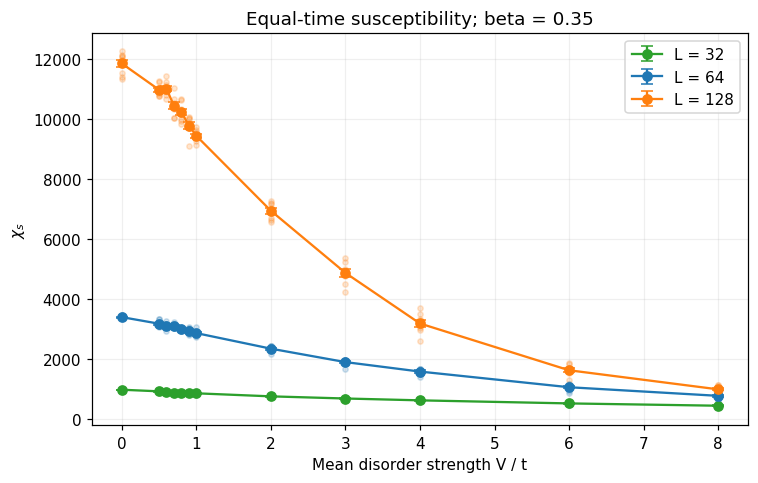

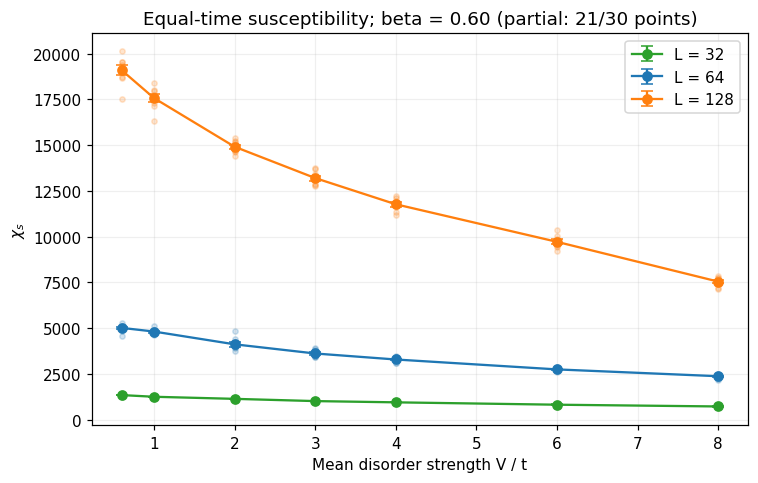

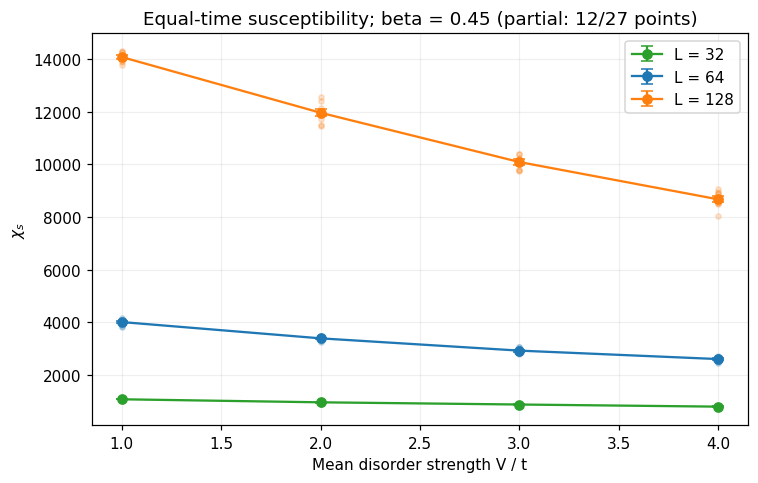

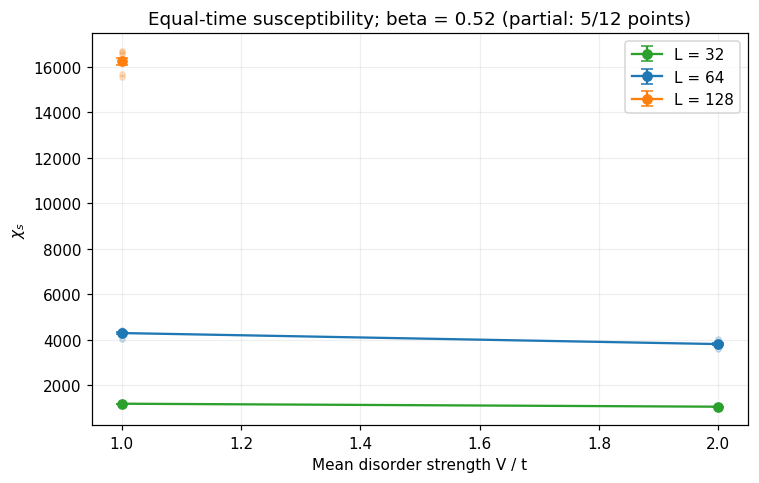

In [3]:
for beta in betas:
    means,errors,samples=means_by_beta[beta],errors_by_beta[beta],samples_by_beta[beta]
    plt.figure()
    for L,colour in zip(sizes,colours):
        x=[V for V in strengths_by_beta[beta] if (L,V) in means]
        if not x:continue
        individual=np.array([samples[L,V][:,0] for V in x])
        plt.scatter(np.repeat(x,individual.shape[1]),individual.ravel(),color=colour,alpha=.2,s=12)
        plt.errorbar(x,[means[L,V][0] for V in x],yerr=[errors[L,V][0] for V in x],fmt='o-',capsize=4,color=colour,label=f'L = {L}')
    plt.xlabel('Mean disorder strength V / t');plt.ylabel(r'$\chi_s$')
    plt.title('Equal-time susceptibility; '+titles[beta])
    if plt.gca().get_legend_handles_labels()[0]:plt.legend()
    plt.grid(alpha=.2);plt.tight_layout()
    plt.savefig(out_by_beta[beta]/'susceptibility_vs_disorder.png',dpi=180);plt.show()



## Scaled susceptibility: beta=0.35, then beta=0.60 underneath

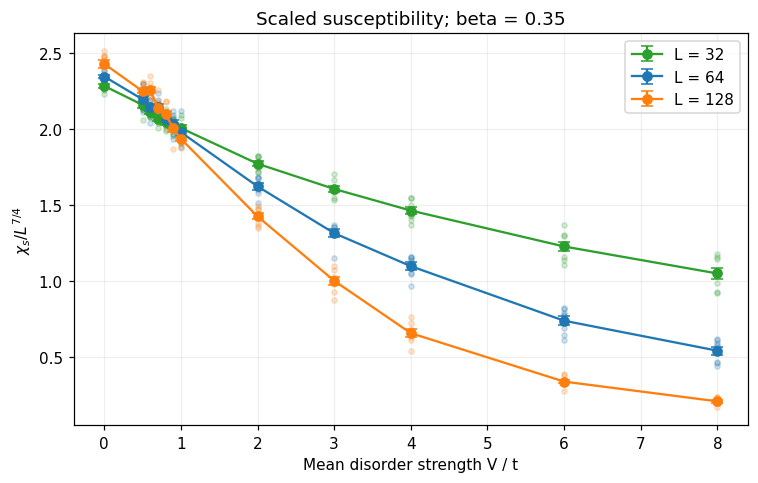

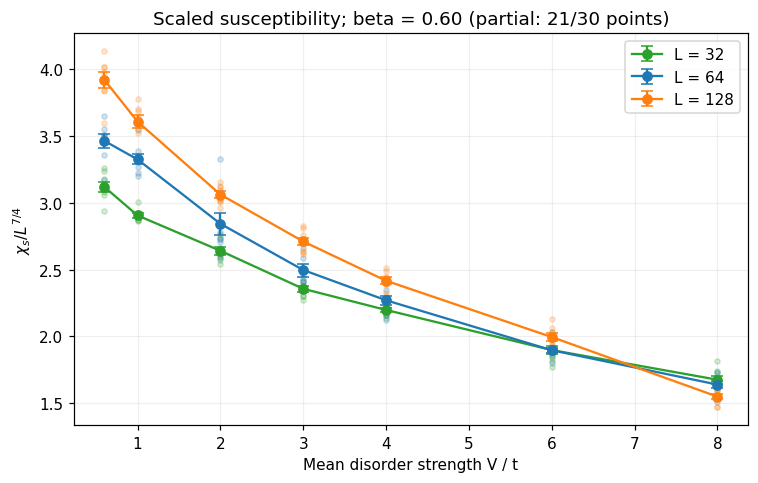

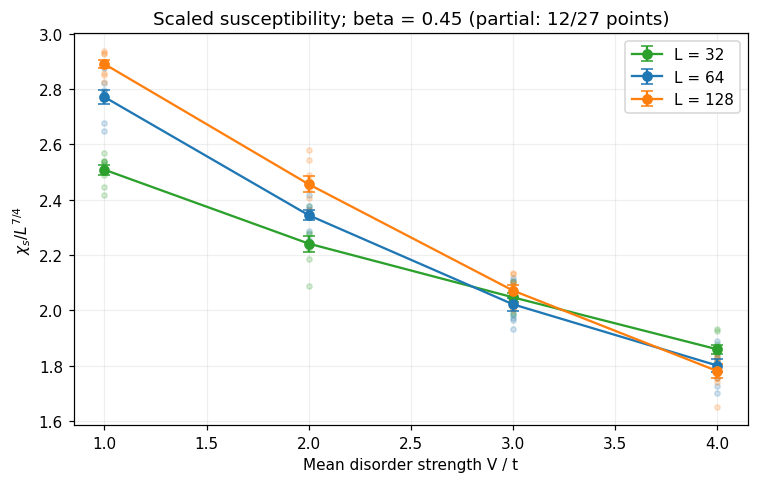

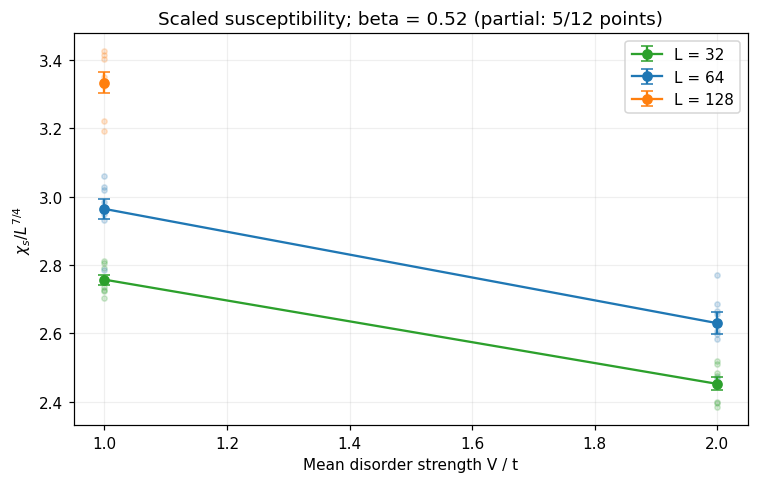

In [4]:
for beta in betas:
    means,errors,samples=means_by_beta[beta],errors_by_beta[beta],samples_by_beta[beta]
    plt.figure()
    for L,colour in zip(sizes,colours):
        x=[V for V in strengths_by_beta[beta] if (L,V) in means]
        if not x:continue
        individual=np.array([samples[L,V][:,0] for V in x])/L**1.75
        plt.scatter(np.repeat(x,individual.shape[1]),individual.ravel(),color=colour,alpha=.2,s=12)
        plt.errorbar(x,[means[L,V][0]/L**1.75 for V in x],yerr=[errors[L,V][0]/L**1.75 for V in x],fmt='o-',capsize=4,color=colour,label=f'L = {L}')
    plt.xlabel('Mean disorder strength V / t');plt.ylabel(r'$\chi_s/L^{7/4}$')
    plt.title('Scaled susceptibility; '+titles[beta])
    if plt.gca().get_legend_handles_labels()[0]:plt.legend()
    plt.grid(alpha=.2);plt.tight_layout()
    plt.savefig(out_by_beta[beta]/'susceptibility_scaled_vs_disorder.png',dpi=180);plt.show()



## Scaled susceptibility over V/t=0.5 to 1, in the same beta order

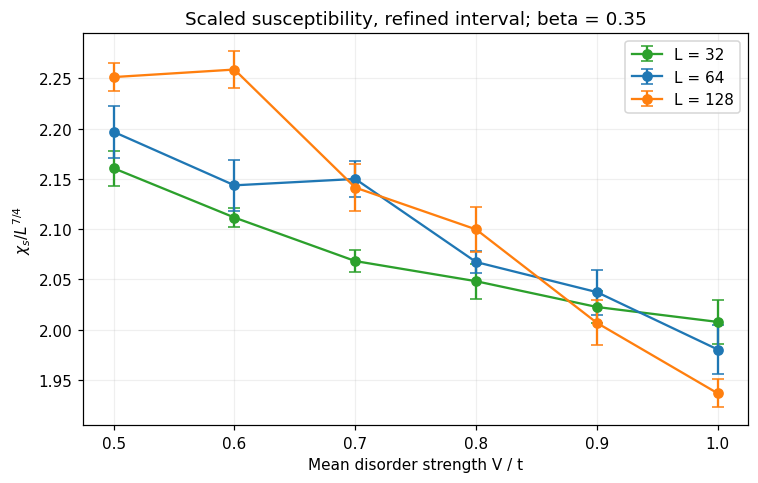

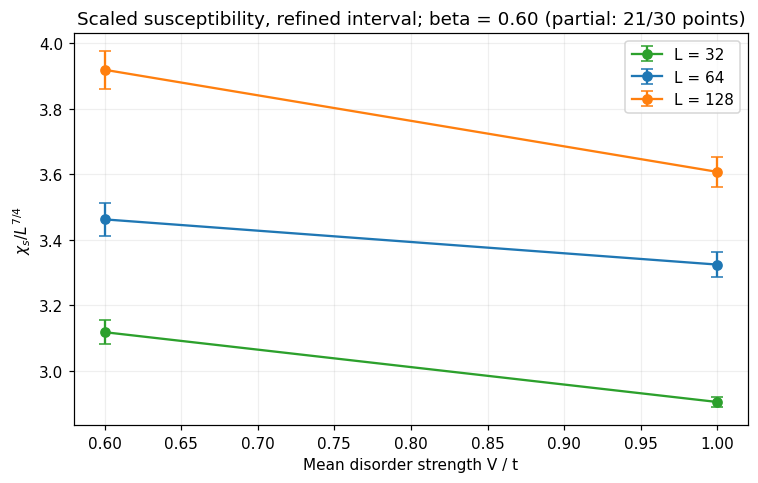

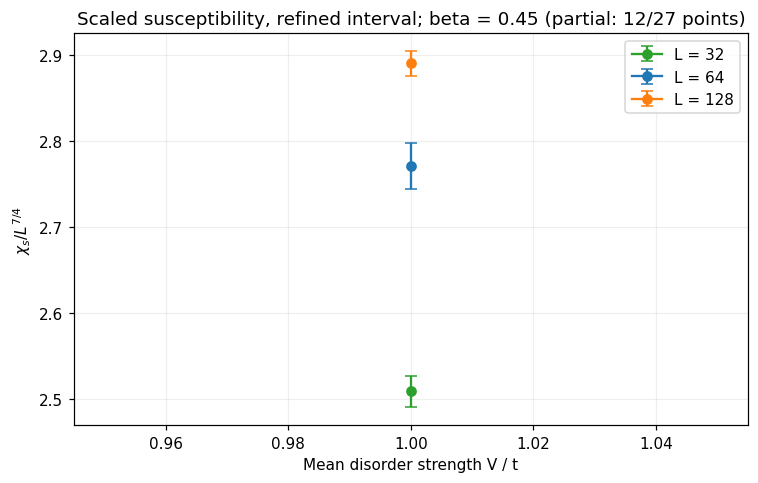

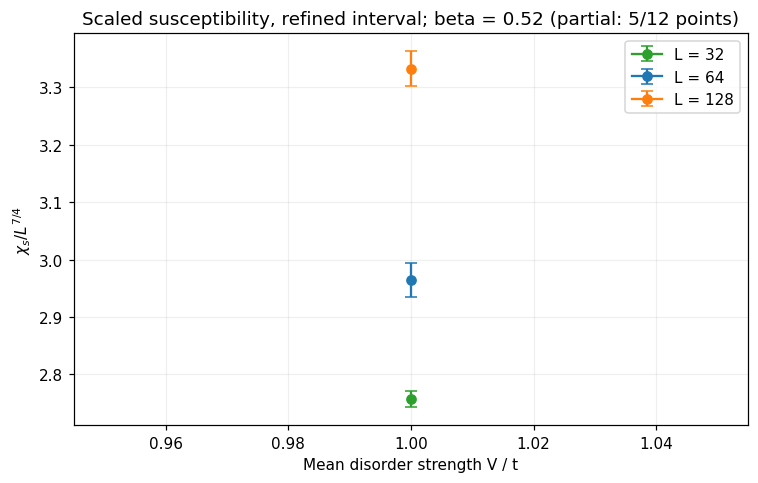

In [5]:
for beta in betas:
    means,errors=means_by_beta[beta],errors_by_beta[beta]
    plt.figure()
    for L,colour in zip(sizes,colours):
        x=[V for V in strengths_by_beta[beta] if .5<=V<=1 and (L,V) in means]
        if not x:continue
        plt.errorbar(x,[means[L,V][0]/L**1.75 for V in x],yerr=[errors[L,V][0]/L**1.75 for V in x],fmt='o-',capsize=4,color=colour,label=f'L = {L}')
    plt.xlabel('Mean disorder strength V / t');plt.ylabel(r'$\chi_s/L^{7/4}$')
    plt.title('Scaled susceptibility, refined interval; '+titles[beta])
    if plt.gca().get_legend_handles_labels()[0]:plt.legend()
    plt.grid(alpha=.2);plt.tight_layout()
    plt.savefig(out_by_beta[beta]/'susceptibility_scaled_refined_interval.png',dpi=180);plt.show()



## Squared x winding: beta=0.35, then beta=0.60 underneath

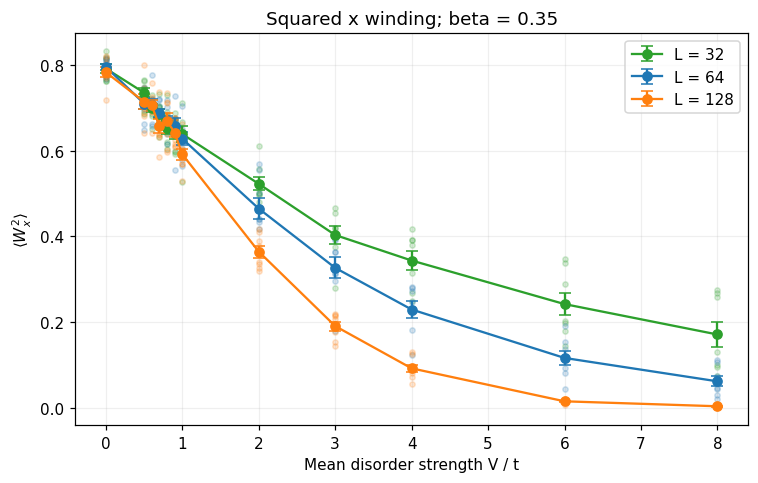

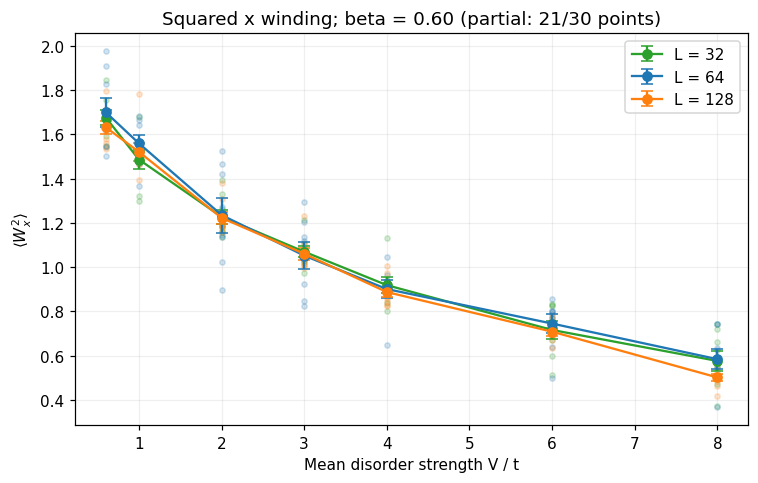

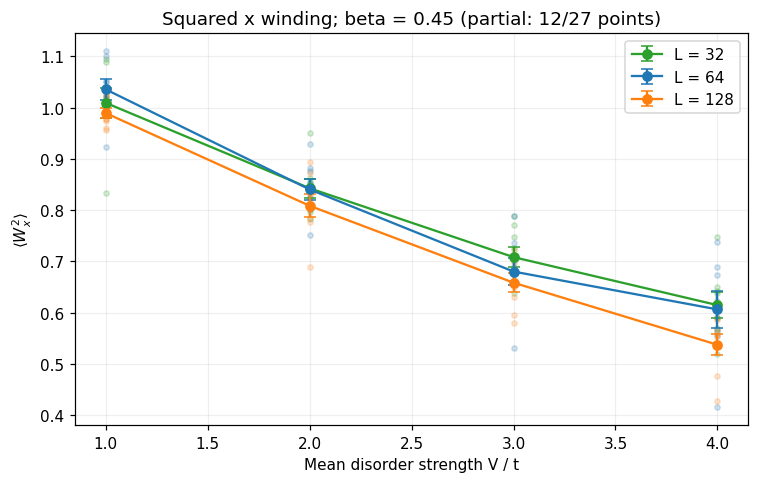

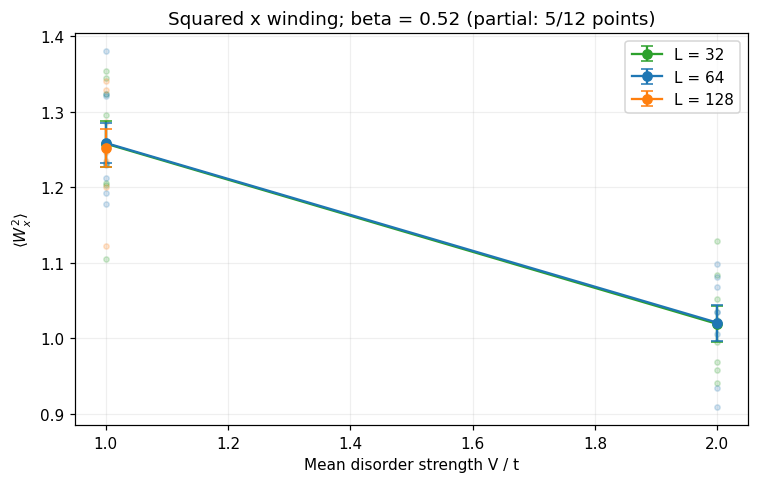

In [6]:
for beta in betas:
    means,errors,samples=means_by_beta[beta],errors_by_beta[beta],samples_by_beta[beta]
    plt.figure()
    for L,colour in zip(sizes,colours):
        x=[V for V in strengths_by_beta[beta] if (L,V) in means]
        if not x:continue
        individual=np.array([samples[L,V][:,1] for V in x])
        plt.scatter(np.repeat(x,individual.shape[1]),individual.ravel(),color=colour,alpha=.2,s=12)
        plt.errorbar(x,[means[L,V][1] for V in x],yerr=[errors[L,V][1] for V in x],fmt='o-',capsize=4,color=colour,label=f'L = {L}')
    plt.xlabel('Mean disorder strength V / t');plt.ylabel(r'$\langle W_x^2\rangle$')
    plt.title('Squared x winding; '+titles[beta])
    if plt.gca().get_legend_handles_labels()[0]:plt.legend()
    plt.grid(alpha=.2);plt.tight_layout()
    plt.savefig(out_by_beta[beta]/'winding_x_vs_disorder.png',dpi=180);plt.show()



## Squared y winding: beta=0.35, then beta=0.60 underneath

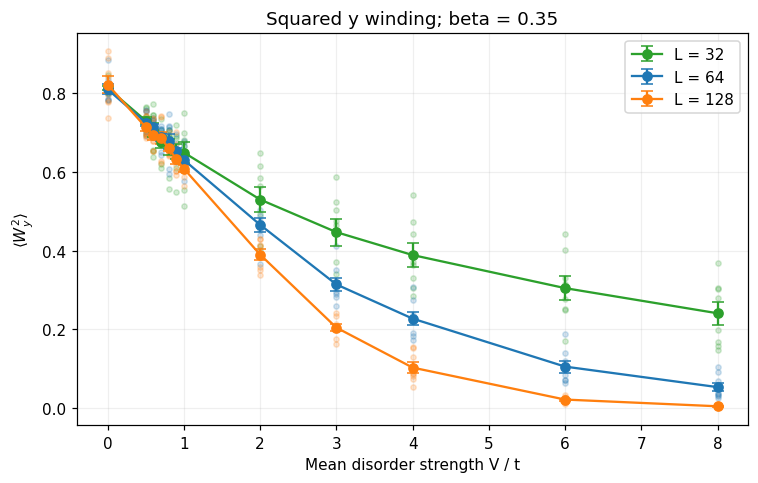

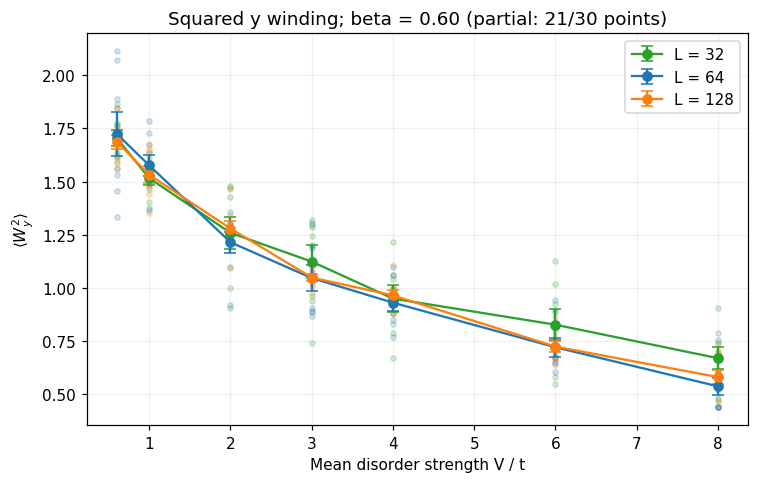

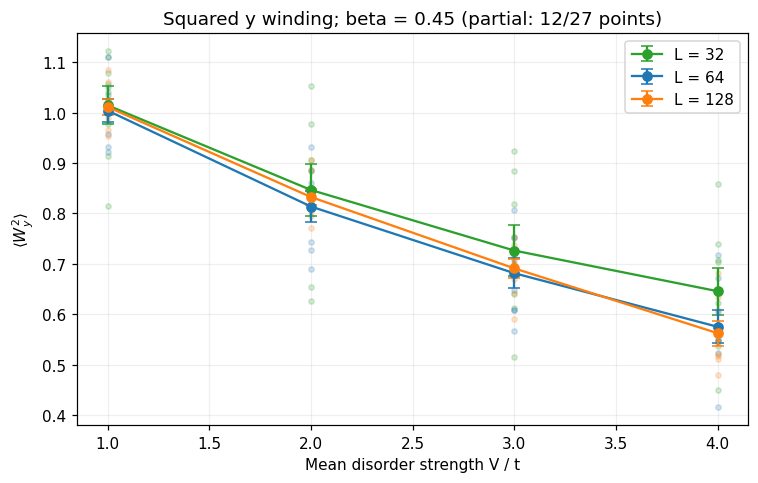

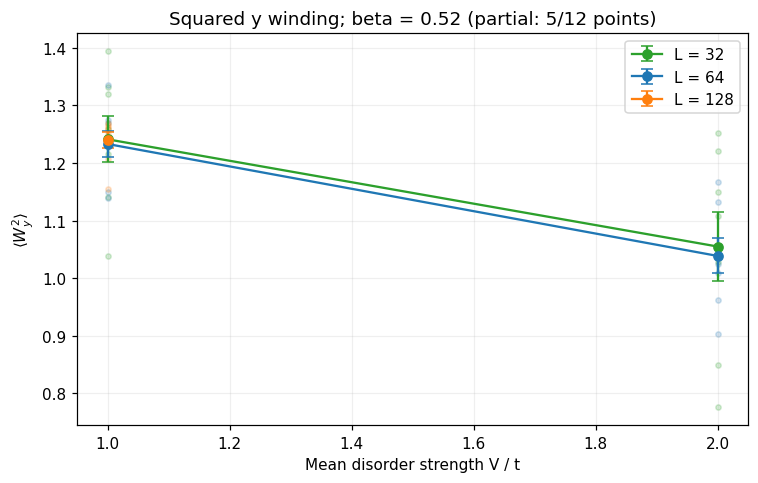

In [7]:
for beta in betas:
    means,errors,samples=means_by_beta[beta],errors_by_beta[beta],samples_by_beta[beta]
    plt.figure()
    for L,colour in zip(sizes,colours):
        x=[V for V in strengths_by_beta[beta] if (L,V) in means]
        if not x:continue
        individual=np.array([samples[L,V][:,2] for V in x])
        plt.scatter(np.repeat(x,individual.shape[1]),individual.ravel(),color=colour,alpha=.2,s=12)
        plt.errorbar(x,[means[L,V][2] for V in x],yerr=[errors[L,V][2] for V in x],fmt='o-',capsize=4,color=colour,label=f'L = {L}')
    plt.xlabel('Mean disorder strength V / t');plt.ylabel(r'$\langle W_y^2\rangle$')
    plt.title('Squared y winding; '+titles[beta])
    if plt.gca().get_legend_handles_labels()[0]:plt.legend()
    plt.grid(alpha=.2);plt.tight_layout()
    plt.savefig(out_by_beta[beta]/'winding_y_vs_disorder.png',dpi=180);plt.show()



## Total squared winding: beta=0.35, then beta=0.60 underneath

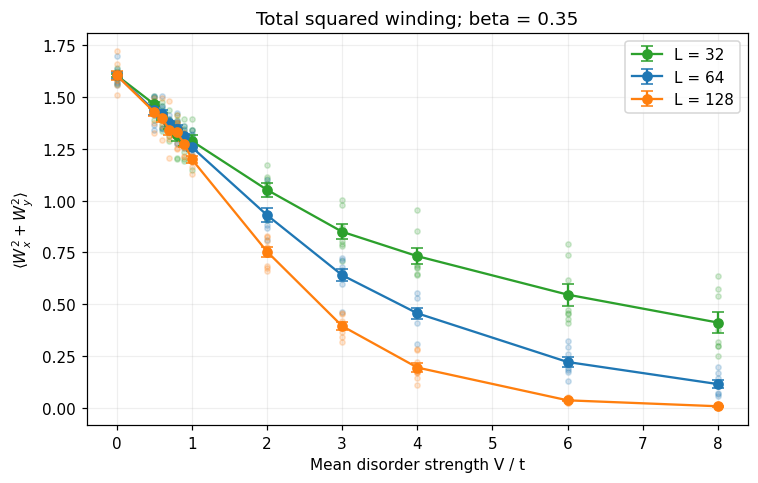

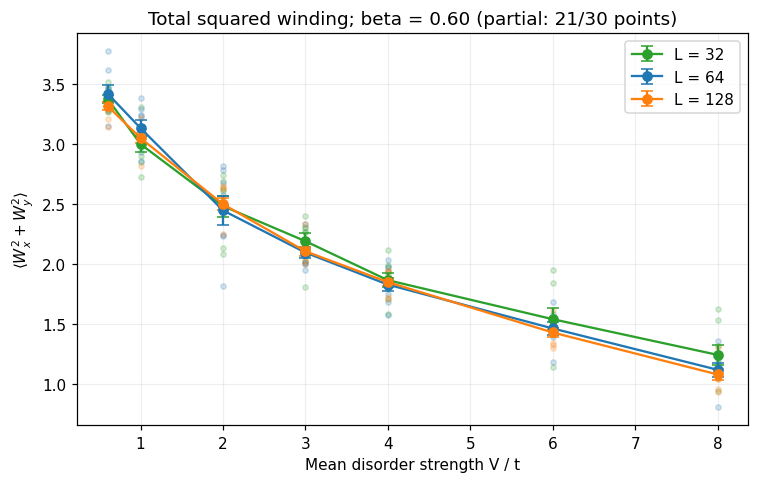

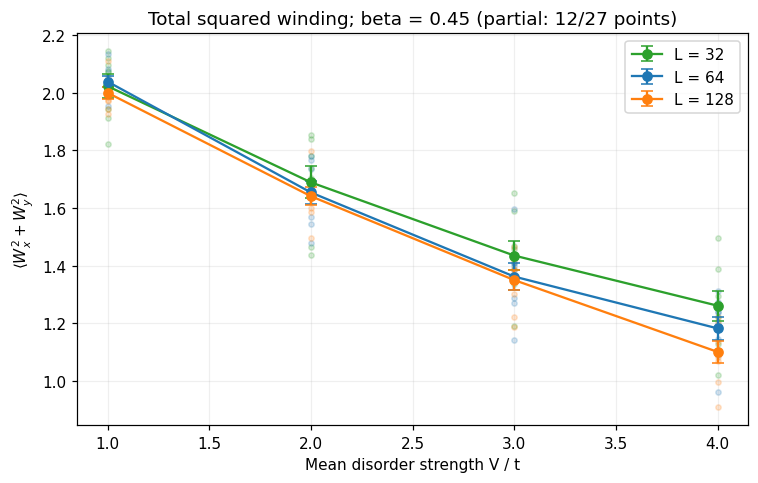

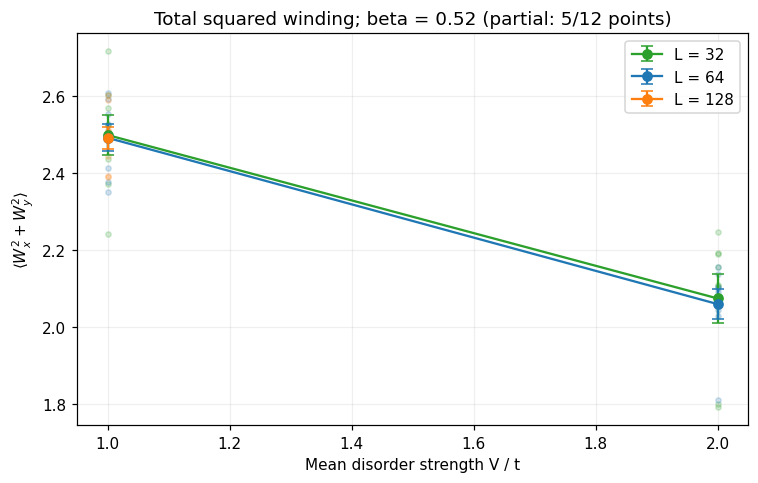

In [8]:
for beta in betas:
    means,errors,samples=means_by_beta[beta],errors_by_beta[beta],samples_by_beta[beta]
    plt.figure()
    for L,colour in zip(sizes,colours):
        x=[V for V in strengths_by_beta[beta] if (L,V) in means]
        if not x:continue
        individual=np.array([samples[L,V][:,3] for V in x])
        plt.scatter(np.repeat(x,individual.shape[1]),individual.ravel(),color=colour,alpha=.2,s=12)
        plt.errorbar(x,[means[L,V][3] for V in x],yerr=[errors[L,V][3] for V in x],fmt='o-',capsize=4,color=colour,label=f'L = {L}')
    plt.xlabel('Mean disorder strength V / t');plt.ylabel(r'$\langle W_x^2+W_y^2\rangle$')
    plt.title('Total squared winding; '+titles[beta])
    if plt.gca().get_legend_handles_labels()[0]:plt.legend()
    plt.grid(alpha=.2);plt.tight_layout()
    plt.savefig(out_by_beta[beta]/'winding_total_vs_disorder.png',dpi=180);plt.show()



## Total winding over V/t=0.5 to 1, in the same beta order

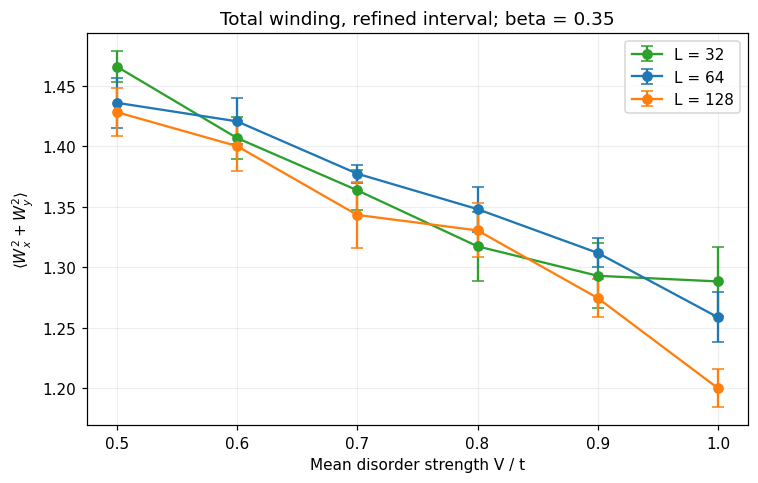

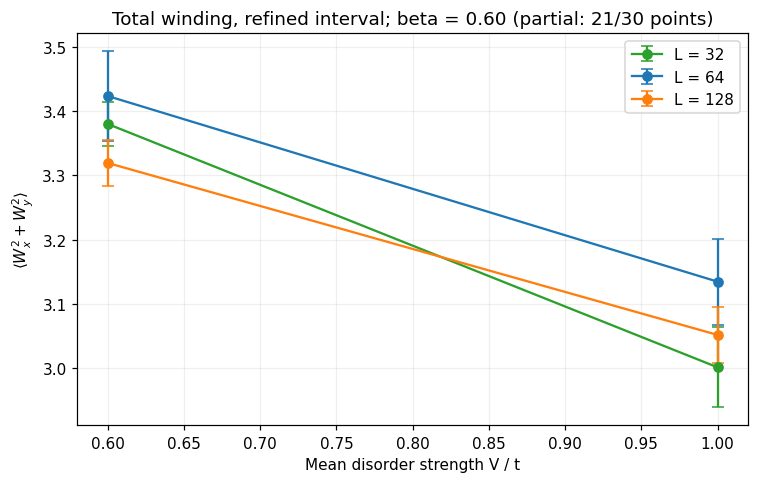

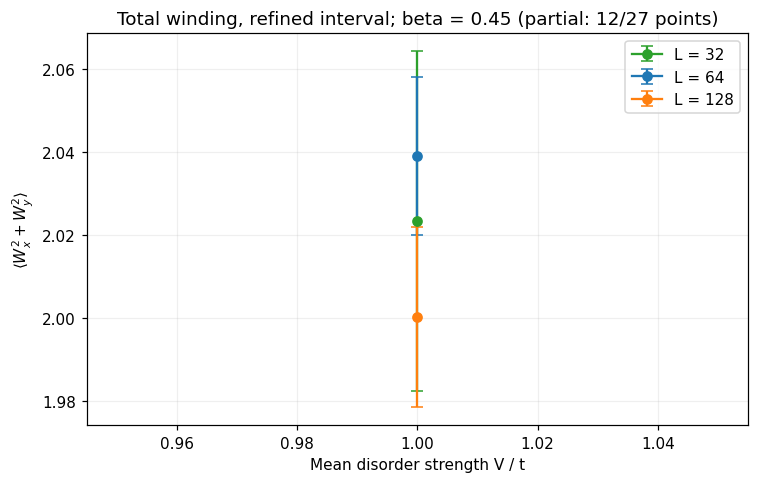

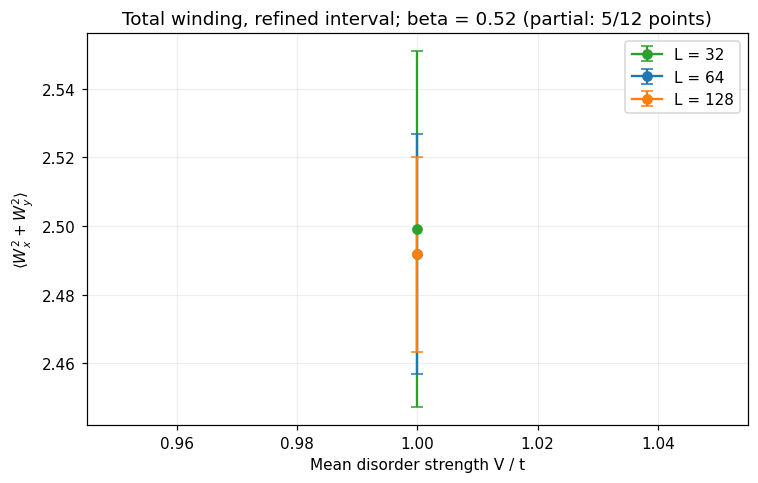

In [9]:
for beta in betas:
    means,errors=means_by_beta[beta],errors_by_beta[beta]
    plt.figure()
    for L,colour in zip(sizes,colours):
        x=[V for V in strengths_by_beta[beta] if .5<=V<=1 and (L,V) in means]
        if not x:continue
        plt.errorbar(x,[means[L,V][3] for V in x],yerr=[errors[L,V][3] for V in x],fmt='o-',capsize=4,color=colour,label=f'L = {L}')
    plt.xlabel('Mean disorder strength V / t');plt.ylabel(r'$\langle W_x^2+W_y^2\rangle$')
    plt.title('Total winding, refined interval; '+titles[beta])
    if plt.gca().get_legend_handles_labels()[0]:plt.legend()
    plt.grid(alpha=.2);plt.tight_layout()
    plt.savefig(out_by_beta[beta]/'winding_total_refined_interval.png',dpi=180);plt.show()



## Susceptibility versus size: beta=0.35, then beta=0.60 underneath

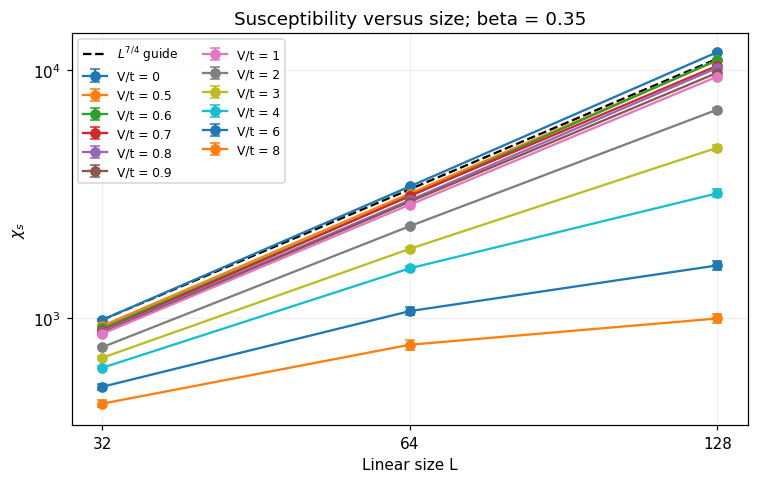

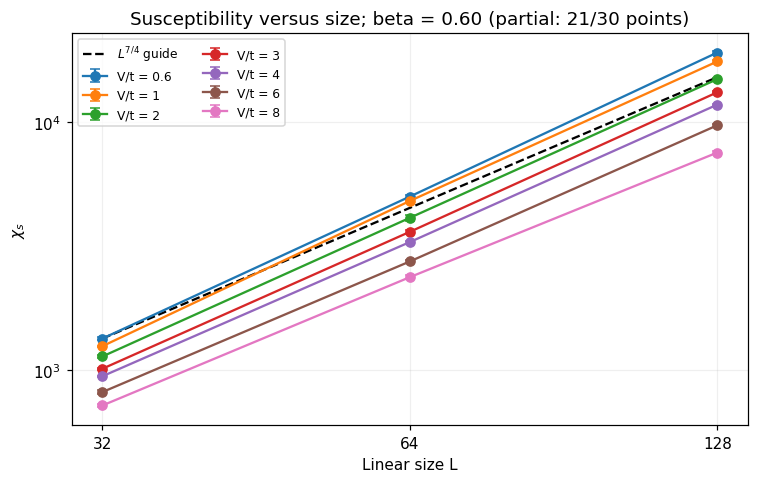

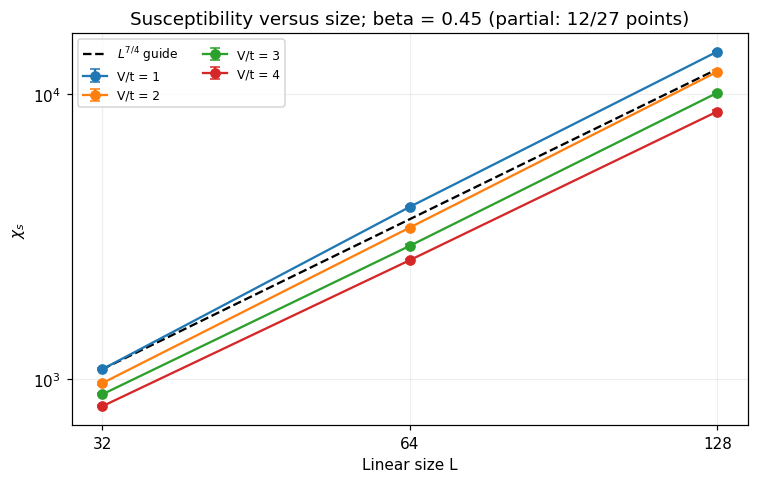

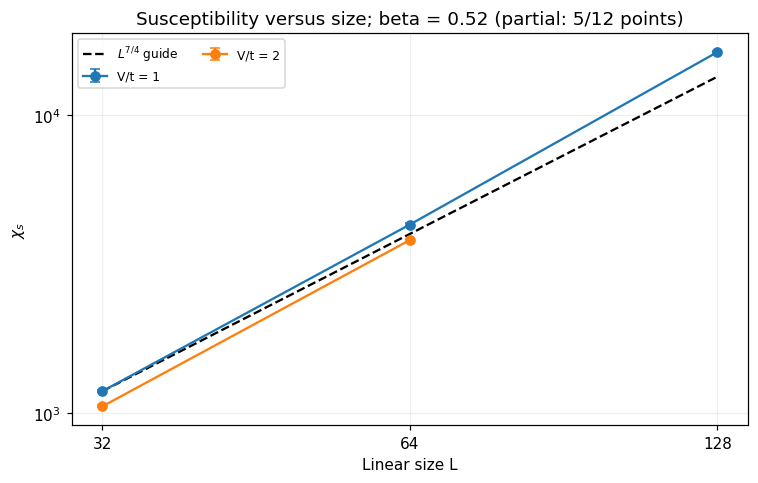

In [10]:
for beta in betas:
    means,errors=means_by_beta[beta],errors_by_beta[beta]
    plt.figure()
    for V in strengths_by_beta[beta]:
        selected=[L for L in sizes if (L,V) in means]
        if not selected:continue
        plt.errorbar(selected,[means[L,V][0] for L in selected],yerr=[errors[L,V][0] for L in selected],fmt='o-',capsize=3,label=f'V/t = {V:g}')
    anchor=strengths_by_beta[beta][0]
    if (sizes[0],anchor) in means:
        guide=np.array(sizes,dtype=float)
        plt.plot(guide,means[sizes[0],anchor][0]*(guide/sizes[0])**1.75,'k--',label=r'$L^{7/4}$ guide')
    plt.xscale('log');plt.yscale('log');plt.xticks(sizes,sizes);plt.minorticks_off()
    plt.xlabel('Linear size L');plt.ylabel(r'$\chi_s$')
    plt.title('Susceptibility versus size; '+titles[beta])
    if plt.gca().get_legend_handles_labels()[0]:plt.legend(ncol=2,fontsize=8)
    plt.grid(alpha=.2);plt.tight_layout()
    plt.savefig(out_by_beta[beta]/'susceptibility_vs_size.png',dpi=180);plt.show()



## Relative susceptibility errors: beta=0.35, then beta=0.60 underneath

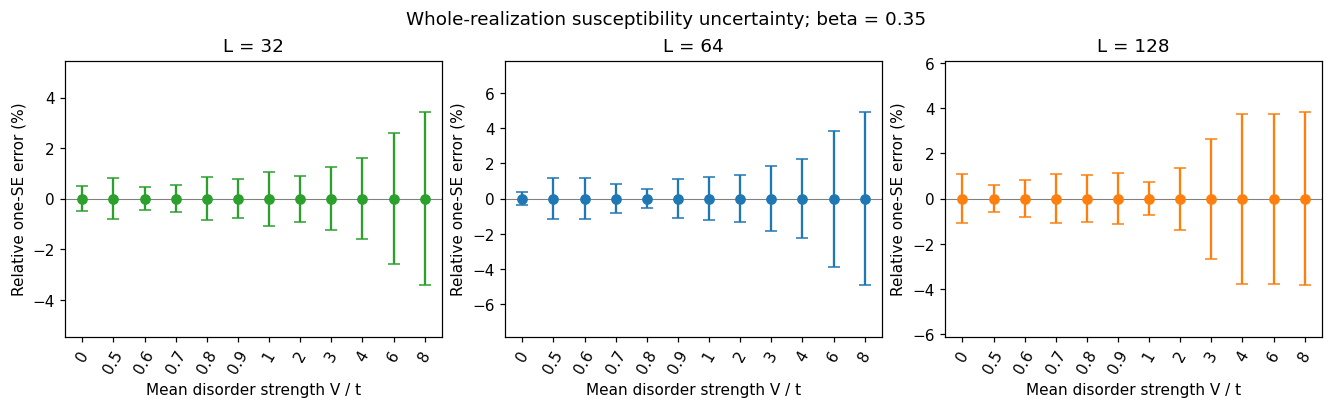

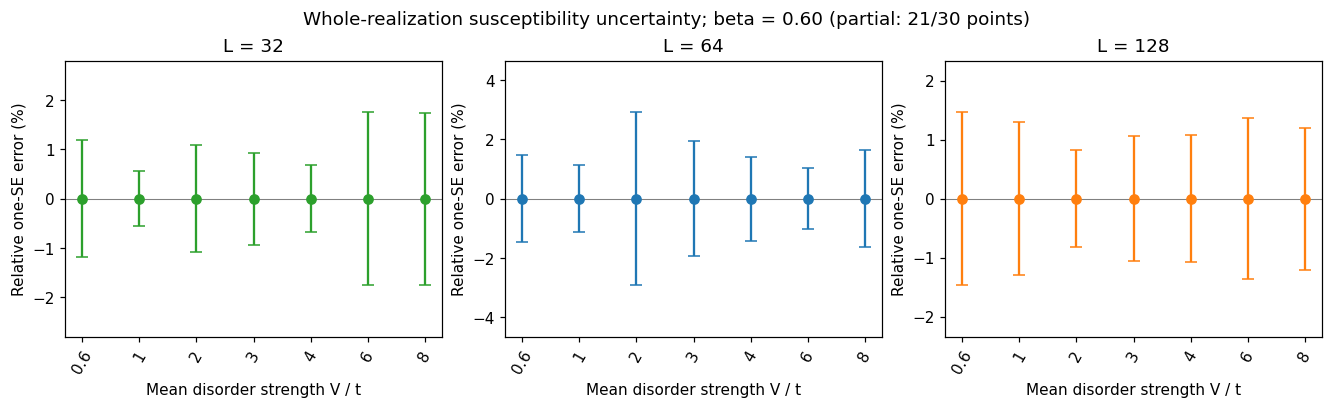

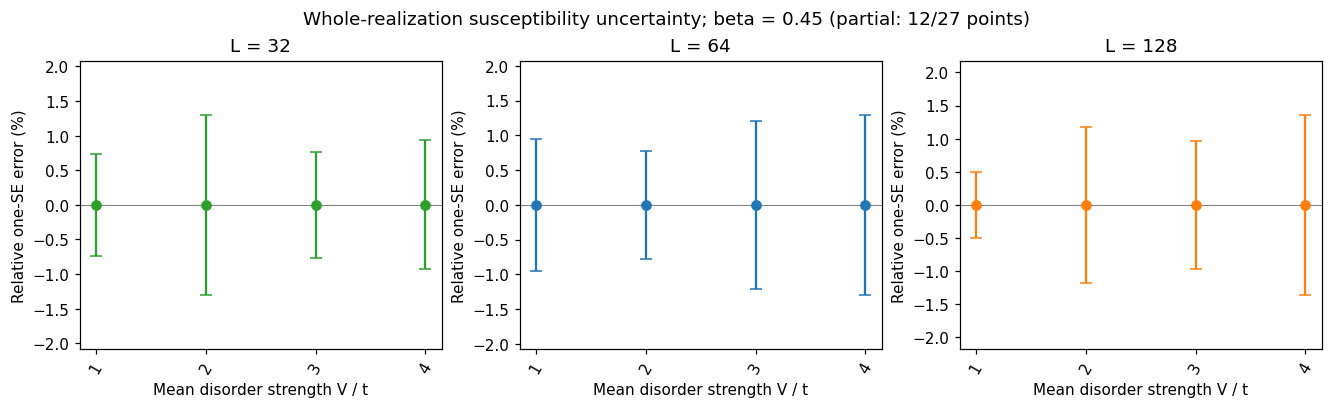

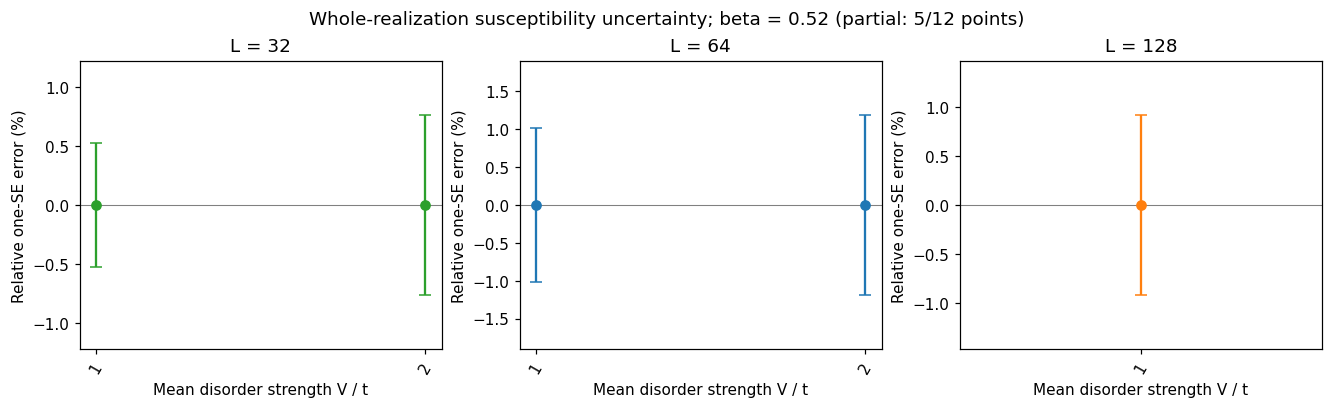

In [11]:
for beta in betas:
    means,errors=means_by_beta[beta],errors_by_beta[beta]
    fig,axes=plt.subplots(1,3,figsize=(12,3.6),constrained_layout=True)
    for L,colour,ax in zip(sizes,colours,axes):
        x=[V for V in strengths_by_beta[beta] if (L,V) in means]
        if x:
            percent=np.array([100*errors[L,V][0]/abs(means[L,V][0]) for V in x])
            ax.errorbar(np.arange(len(x)),np.zeros(len(x)),yerr=percent,fmt='o',capsize=4,color=colour)
            ax.set_xticks(np.arange(len(x)),[f'{V:g}' for V in x],rotation=60)
            ax.set_ylim(-1.6*max(percent.max(),.01),1.6*max(percent.max(),.01))
        else:ax.text(.5,.5,'No complete point yet',ha='center',transform=ax.transAxes)
        ax.axhline(0,color='.5',lw=.7);ax.set_title(f'L = {L}')
        ax.set_xlabel('Mean disorder strength V / t');ax.set_ylabel('Relative one-SE error (%)')
    fig.suptitle('Whole-realization susceptibility uncertainty; '+titles[beta])
    plt.savefig(out_by_beta[beta]/'susceptibility_relative_errors.png',dpi=180);plt.show()

